# TP2 — Détection de menaces radar

**Étudiants :** Aimine Meddeb / Paolo Cheype.

**Objectif :** determiner si un signal PDW est `menace` (1) / `nonmenace` (0).

## Pipeline du notebook

1. **Setup** — imports et chemins
2. **Extraction de features** 
3. **Tenseur / DataFrame** — construction de `X_train`, `X_valid`, `X_test` avec les features extraites
4. **Exploration rapide** — visualisation des distributions
5. **Entraînement** — 5 modèles + `GridSearchCV` sur le jeu de validation
6. **Évaluation** 



## 1. Setup


In [12]:
# !pip install -U numpy scikit-learn matplotlib pandas seaborn -q

In [13]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import PredefinedSplit, GridSearchCV
from sklearn.metrics import (classification_report,ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score)

DATA_DIR = Path("donnees")
RANDOM_STATE = 42


In [14]:
from IPython.core.display import HTML
HTML("""
<style>
.consignes{
  font-weight: bold;
  color: #3256a8;
  background-color: #edebdf
}
</style>
""")

## 2. Extraction de features



In [15]:
# Fonctions utiles

def clean_features(feats):
    """Remplace NaN et Inf par 0."""
    clean = {}
    for k, v in feats.items():
        v = float(v)
        if np.isnan(v) or np.isinf(v):
            clean[k] = 0.0
        else:
            clean[k] = v
    return clean


def load_pdw(pdw):
    """Charge un .npz et trie les impulsions par date."""
    date = np.array(pdw["date"], dtype=float)
    order = np.argsort(date)
    return {
        "date": date[order],
        "largeur": np.array(pdw["largeur"], dtype=float)[order],
        "frequence": np.array(pdw["frequence"], dtype=float)[order],
        "puissance": np.array(pdw["puissance"], dtype=float)[order],
        "theta": np.array(pdw["theta"], dtype=float)[order],
        "phi": np.array(pdw["phi"], dtype=float)[order],
    }


In [16]:
 
"""
def extract_features_base(pdw) -> dict:
    
    d = load_pdw(pdw)
    date = d["date"]
    largeur = d["largeur"]
    frequence = d["frequence"]
    puissance = d["puissance"]
    theta = d["theta"]
    phi = d["phi"]

    # PRI = temps entre deux impulsions
    pri = np.diff(date)
    pri = pri[pri > 0]

    feats = {
        "n_pulses": float(len(date)),                    # nombre d'impulsions détectées
        "duree_ms": float(date[-1] - date[0]) if len(date) > 0 else 0.0,  # durée du signal

        "pri_mean": float(np.mean(pri)) if len(pri) else 0.0,
        "pri_std": float(np.std(pri)) if len(pri) else 0.0,

        "frequence_mean": float(np.mean(frequence)),
        "frequence_std": float(np.std(frequence)),

        "largeur_mean": float(np.mean(largeur)),
        "largeur_std": float(np.std(largeur)),

        "puissance_mean": float(np.mean(puissance)),
        "puissance_std": float(np.std(puissance)),
        "puissance_max": float(np.max(puissance)),
        "puissance_min": float(np.min(puissance)),

        "theta_mean": float(np.mean(theta)),
        "theta_std": float(np.std(theta)),

        "phi_mean": float(np.mean(phi)),
        "phi_std": float(np.std(phi)),
    }
    return clean_features(feats)
"""

# Binôme A


def extract_features_avancees(pdw) -> dict:
    """Quelques features supplémentaires faciles à interpréter."""
    d = load_pdw(pdw)
    date = d["date"]
    largeur = d["largeur"]
    frequence = d["frequence"]
    puissance = d["puissance"]
    theta = d["theta"]
    phi = d["phi"]

    pri = np.diff(date)
    pri = pri[pri > 0]

    feats = {
        # PRI
        "pri_median": float(np.median(pri)) if len(pri) else 0.0,   # rythme typique
        "pri_min": float(np.min(pri)) if len(pri) else 0.0,
        "pri_max": float(np.max(pri)) if len(pri) else 0.0,

        # Angles : amplitude observée pendant le passage (max - min)
        "theta_range": float(np.max(theta) - np.min(theta)),
        "phi_range": float(np.max(phi) - np.min(phi)),

        # Fréquence / largeur : bande et variation de durée d'impulsion
        "frequence_span": float(np.max(frequence) - np.min(frequence)),
        "largeur_span": float(np.max(largeur) - np.min(largeur)),

        # Puissance : contraste entre le pic et la moyenne
        "puissance_peak_to_mean": float(np.max(puissance) - np.mean(puissance)),
    }
    return clean_features(feats)


## 3. Construction des DataFrames



In [17]:
def build_feature_tensor(data_dir, labels_json_path, extract_fn, return_labels=True):
    """
    Construit un DataFrame avec lea features séléctionnées

    Parameters
    ----------
    data_dir : dossier des .npz
    labels_json_path : JSON avex les label de chaque fichier (menance ou ami)
    extract_fn : dictionnaire de features
    return_labels : si True, retourne aussi les labels

    Returns
    -------
    X : le dataframe
    y : les valeur des labels
    """
    data_dir = Path(data_dir)
    with open(labels_json_path, encoding="utf-8") as f:
        labels_dict = json.load(f)

    rows, index, y_list = [], [], []
    for signal_name, label_str in labels_dict.items():
        pdw = np.load(data_dir / f"{signal_name}.npz")
        rows.append(extract_fn(pdw))
        index.append(signal_name)
        y_list.append(1 if label_str == "menace" else 0)

    X = pd.DataFrame(rows, index=index)
    if return_labels:
        y = pd.Series(y_list, index=index, name="y", dtype=int)
        return X, y
    return X




### 3.1 Binôme B — features de base + labels


In [ ]:


"""X_train_B, y_train = build_feature_tensor(
    DATA_DIR / "train",
    DATA_DIR / "train_labels.json",
    extract_features_base,
)

X_valid_B, y_valid = build_feature_tensor(
    DATA_DIR / "valid",
    DATA_DIR / "valid_labels.json",
    extract_features_base,
)

X_test_B, y_test = build_feature_tensor(
    DATA_DIR / "test",
    DATA_DIR / "test_labels.json",
    extract_features_base,
)

print("Train B :", X_train_B.shape)
print("Valid B :", X_valid_B.shape)
print("Test  B :", X_test_B.shape)
X_train_B.head()"""


### 3.2 Binôme A


In [25]:


X_train_A, y_train = build_feature_tensor(
    DATA_DIR / "train",
    DATA_DIR / "train_labels.json",
    extract_features_avancees,
    return_labels=True,
)

X_valid_A, y_valid = build_feature_tensor(
    DATA_DIR / "valid",
    DATA_DIR / "valid_labels.json",
    extract_features_avancees,
    return_labels=True,
)

X_test_A , y_test= build_feature_tensor(
    DATA_DIR / "test",
    DATA_DIR / "test_labels.json",
    extract_features_avancees,
    return_labels=True,
)

print("Train A :", X_train_A.shape)
print("Valid A :", X_valid_A.shape)
print("Test  A :", X_test_A.shape)
X_train_A.head()


Train A : (2000, 8)
Valid A : (1000, 8)
Test  A : (1000, 8)


,pri_median,pri_min,pri_max,theta_range,phi_range,frequence_span,largeur_span,puissance_peak_to_mean
pdw-0,4.0,1.0,80.0,1.159668,1.203125,0.093750,0.019958,21.667044
pdw-1,4.0,2.0,60.0,1.121826,1.150391,0.101562,0.020020,23.363846
pdw-2,4.0,2.0,56.0,1.307617,1.140625,0.067383,0.019897,19.946600
pdw-3,3.5,1.0,48.0,1.294922,1.213867,0.093750,0.020020,24.957262
pdw-4,2.0,0.5,152.0,1.226562,1.228027,0.055664,0.019989,17.048291


### 3.3 On colle A et B ensemble


In [26]:
# On met les colonnes B puis A côte à côte
"""
X_train = pd.concat([X_train_B, X_train_A], axis=1)
X_valid = pd.concat([X_valid_B, X_valid_A], axis=1)
X_test = pd.concat([X_test_B, X_test_A], axis=1)

print("X_train :", X_train.shape)
print("Colonnes :", list(X_train.columns))
X_train.head()
"""
X_train = X_train_A
X_valid = X_valid_A
X_test = X_test_A



## 4. Exploration rapide

On regarde un peu les données avant d'entraîner les modèles.


y
1    1012
0     988
Name: count, dtype: int64


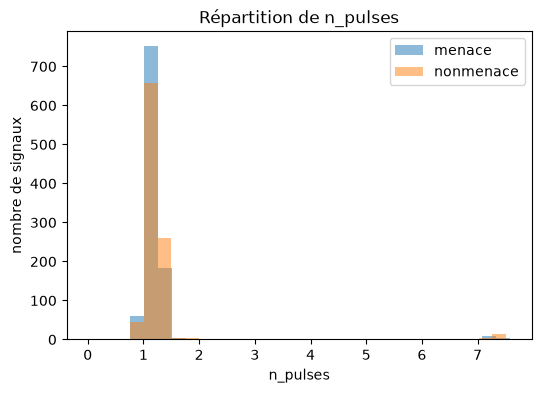

In [ ]:
# Combien de menace / nonmenace dans le train
print(y_train.value_counts())

# Histogramme d'une feature
plt.figure(figsize=(6, 4))
plt.hist(X_train.loc[y_train == 1, "theta_range"], bins=30, alpha=0.5, label="menace")
plt.hist(X_train.loc[y_train == 0, "theta_range"], bins=30, alpha=0.5, label="nonmenace")
plt.xlabel("n_pulses")
plt.ylabel("nombre de signaux")
plt.legend()
plt.title("Répartition de n_pulses")
plt.show()


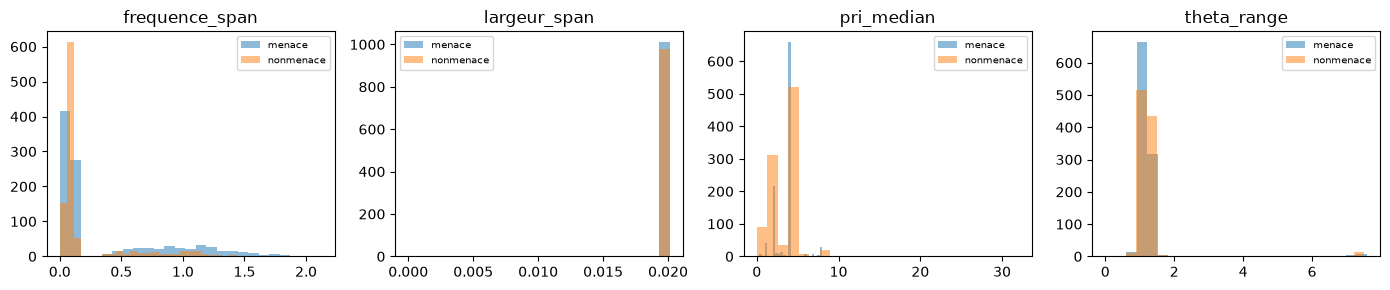

In [33]:
features_a_voir = ["frequence_span", "largeur_span", "pri_median", "theta_range"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, feat in zip(axes, features_a_voir):
    ax.hist(X_train.loc[y_train == 1, feat], bins=25, alpha=0.5, label="menace")
    ax.hist(X_train.loc[y_train == 0, feat], bins=25, alpha=0.5, label="nonmenace")
    ax.set_title(feat)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


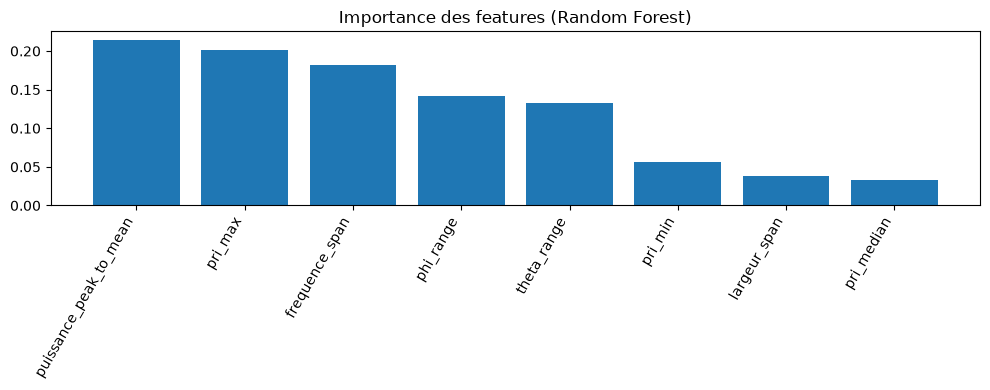

puissance_peak_to_mean    0.214767
pri_max                   0.201968
frequence_span            0.182478
phi_range                 0.141754
theta_range               0.132789
pri_min                   0.055859
largeur_span              0.037922
pri_median                0.032462
dtype: float64


In [34]:
rf_temp = RandomForestClassifier(n_estimators=100, random_state=42)
rf_temp.fit(X_train, y_train)

importances = pd.Series(rf_temp.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10, 4))
plt.bar(importances.index, importances.values)
plt.xticks(rotation=60, ha="right")
plt.title("Importance des features (Random Forest)")
plt.tight_layout()
plt.show()

print(importances.head(8))


## 5. Entraînement des modèles

On teste 5 classifieurs. Pour LR, SVM et k-NN on normalise avec `StandardScaler`.  
Les hyperparamètres sont choisis avec un GridSearch sur le jeu de validation.


In [ ]:
# Les 5 modèles
models = {
    "RandomForest": RandomForestClassifier(random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(random_state=42)),
    ]),
    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier()),
    ]),
}

# grills d'hyperparamètres 
param_grids = {
    "RandomForest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
    },
    "HistGradientBoosting": {
        "learning_rate": [0.05, 0.1],
        "max_depth": [None, 5, 10],
    },
    "LogisticRegression": {
        "clf__C": [0.1, 1.0, 10.0],
    },
    "SVM": {
        "clf__C": [0.5, 1.0, 5.0],
        "clf__gamma": ["scale", 0.1],
    },
    "kNN": {
        "clf__n_neighbors": [3, 5, 11],
        "clf__weights": ["uniform", "distance"],
    },
}

print("Modèles :", list(models.keys()))


Modèles : ['RandomForest', 'HistGradientBoosting', 'LogisticRegression', 'SVM', 'kNN']


In [ ]:
X_train_val = pd.concat([X_train, X_valid])
y_train_val = pd.concat([y_train, y_valid])

# -1 = train, 0 = valid
folds = np.array([-1] * len(X_train) + [0] * len(X_valid))
cv_valid = PredefinedSplit(folds)

best_models = {}
resultats_valid = []

for name in models:
    print("\n===", name, "===")
    search = GridSearchCV(
        models[name],
        param_grids[name],
        scoring="f1",
        cv=cv_valid,
        n_jobs=1,
    )
    search.fit(X_train_val, y_train_val)

    best_models[name] = search.best_estimator_
    resultats_valid.append({
        "modele": name,
        "best_params": search.best_params_,
        "f1_valid": search.best_score_,
    })
    print("meilleurs params :", search.best_params_)
    print("F1 valid :", round(search.best_score_, 4))

pd.DataFrame(resultats_valid).sort_values("f1_valid", ascending=False)



=== RandomForest ===
meilleurs params : {'max_depth': None, 'n_estimators': 100}
F1 valid : 0.7575

=== HistGradientBoosting ===
meilleurs params : {'learning_rate': 0.05, 'max_depth': 10}
F1 valid : 0.7642

=== LogisticRegression ===
meilleurs params : {'clf__C': 1.0}
F1 valid : 0.5854

=== SVM ===
meilleurs params : {'clf__C': 5.0, 'clf__gamma': 0.1}
F1 valid : 0.6675

=== kNN ===
meilleurs params : {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}
F1 valid : 0.6877


,modele,best_params,f1_valid
1,HistGradientBoosting,"{'learning_rate': 0.05, 'max_depth': 10}",0.764161
0,RandomForest,"{'max_depth': None, 'n_estimators': 100}",0.757544
4,kNN,"{'clf__n_neighbors': 5, 'clf__weights': 'unifo...",0.687685
3,SVM,"{'clf__C': 5.0, 'clf__gamma': 0.1}",0.667450
2,LogisticRegression,{'clf__C': 1.0},0.585417


## 6. Évaluation sur le test

Pour chaque modèle : rapport de classification + matrice de confusion.


RandomForest
              precision    recall  f1-score   support

   nonmenace       0.71      0.83      0.77       482
      menace       0.81      0.69      0.75       518

    accuracy                           0.76      1000
   macro avg       0.76      0.76      0.76      1000
weighted avg       0.76      0.76      0.76      1000

HistGradientBoosting
              precision    recall  f1-score   support

   nonmenace       0.73      0.83      0.78       482
      menace       0.82      0.71      0.76       518

    accuracy                           0.77      1000
   macro avg       0.77      0.77      0.77      1000
weighted avg       0.77      0.77      0.77      1000

LogisticRegression
              precision    recall  f1-score   support

   nonmenace       0.59      0.66      0.62       482
      menace       0.64      0.57      0.61       518

    accuracy                           0.61      1000
   macro avg       0.62      0.62      0.61      1000
weighted avg       0.

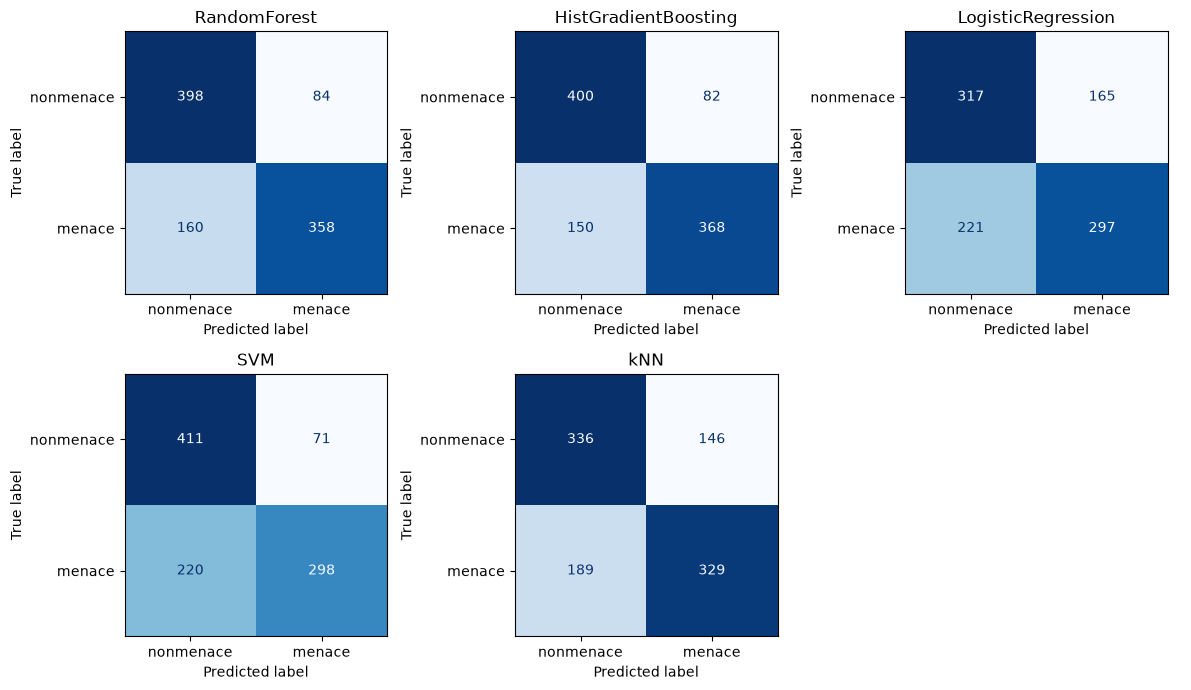

                      accuracy  precision  recall      f1
modele                                                   
HistGradientBoosting     0.768     0.8178  0.7104  0.7603
RandomForest             0.756     0.8100  0.6911  0.7458
SVM                      0.709     0.8076  0.5753  0.6719
kNN                      0.665     0.6926  0.6351  0.6626
LogisticRegression       0.614     0.6429  0.5734  0.6061


,accuracy,precision,recall,f1
modele,,,,
HistGradientBoosting,0.768,0.817778,0.710425,0.760331
RandomForest,0.756,0.809955,0.691120,0.745833
SVM,0.709,0.807588,0.575290,0.671928
kNN,0.665,0.692632,0.635135,0.662638
LogisticRegression,0.614,0.642857,0.573359,0.606122


In [ ]:
lignes = []

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, name in enumerate(best_models):
    model = best_models[name]
    y_pred = model.predict(X_test)

    print("=" * 50)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["nonmenace", "menace"]))

    lignes.append({
        "modele": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["nonmenace", "menace"],
        cmap="Blues",
        colorbar=False,
        ax=axes[i],
    )
    axes[i].set_title(name)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

# tableau récap
df_test = pd.DataFrame(lignes).set_index("modele").sort_values("f1", ascending=False)
print(df_test.round(4))
df_test
